<a href="https://colab.research.google.com/github/adamarsyadfaizin/PCVK26_10_Adam/blob/main/PCVK_W9_244107020164_Adam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 9 – Praktikum Morfologi Citra
**Pengolahan Citra dan Visi Komputer** – Erosi, Dilasi, Opening, Closing, Top-hat, Black-hat, Skeleton, Thinning


## Percobaan 1 – Menyiapkan Google Colab


In [1]:
from google.colab import drive
drive.mount('/content/drive')
PATH = '/content/drive/MyDrive/PCVK/Images/244107020164/'

Mounted at /content/drive


### **Kesimpulan & Analisis**

Begitu Google Drive sukses tersambung (*mounted*), folder penyimpanan bisa langsung diakses lewat path `/content/drive`. Karena semua gambar dibaca menggunakan variabel `PATH`, cukup ganti satu baris kode saja kalau folder asalnya berpindah tempat. Sangat praktis dan efisien.

### **Penjelasan**

- **cv2**: Library utama untuk membaca gambar dan memproses operasi morfologi citra.
- **numpy**: Digunakan untuk membuat matriks kernel serta manipulasi array.
- **matplotlib**: Digunakan untuk menampilkan gambar secara berdampingan agar terlihat rapi.
- **daftar_file**: List berisi nama-nama file gambar agar proses bisa berjalan otomatis menggunakan perulangan.

In [2]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
daftar_file = ['plat.jpg', 'noisy_text.png']

### **Kesimpulan & Analisis**

Semua library dasar sudah siap tempur! Untuk library khusus analisis lanjutan seperti skeleton dan thinning (`scikit-image`), impor library cukup dilakukan saat masuk ke percobaan bersangkutan saja.

### **Penjelasan**

- **Dilasi**: Operasi untuk menebalkan area putih (objek) di dalam gambar biner.
- **Cara Kerja**: Piksel hasil akan bernilai putih (nilai maksimal) jika ada minimal satu piksel putih yang tertutup oleh cakupan *Structuring Element* (SE) atau kernel.
- **Kernel**: Di sini digunakan matriks persegi 5x5 yang berisi angka 1 di semua elemennya.

In [3]:
def dilasi_citra(F,w):
  p,q= F.shape
  imgD= np.zeros((p,q), dtype=np.uint8)
  SED= np.ones((w,w), dtype=np.uint8)
  constant1= (w-1)//2
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

Citra: plat.jpg


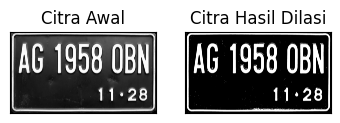

Citra: noisy_text.png


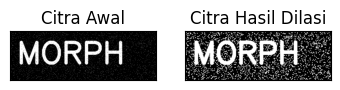

In [4]:
for nama in daftar_file:
    print('Citra:', nama)
    img_d= cv2.imread(f'{PATH}/{nama}',0)
    ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
    w=3
    imgD = dilasi_citra(thresh,w)
    plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

Citra: plat.jpg


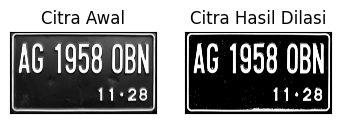

Citra: noisy_text.png


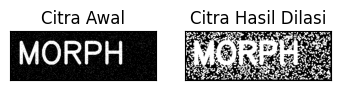

In [5]:
for nama in daftar_file:
    print('Citra:', nama)
    img_d= cv2.imread(f'{PATH}/{nama}',0)
    ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
    w=5
    imgD = dilasi_citra(thresh,w)
    plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

### **Kesimpulan & Analisis**

- **Gambar Plat**: Karakter huruf, angka, garis tepi, hingga tulisan kecil `11 • 28` terlihat menjadi lebih tebal dan solid.
- **Gambar Teks Bising**: Huruf memang semakin tebal, tetapi bintik-bintik *noise* putih di latar belakang juga ikut membesar dan menumpuk. Hal ini terjadi karena proses dilasi menebalkan seluruh objek putih tanpa pemisahan.
- **Ukuran**: Proses manual ini menerapkan kernel persegi berukuran 3x3 dan 5x5.

### **Penjelasan**

- **cv2.dilate()**: Fungsi bawaan OpenCV untuk menjalankan proses dilasi cepat menggunakan kernel persegi 3x3.
- **Grayscale**: Sebelum proses dilasi dijalankan, gambar dikonversi terlebih dahulu dari format warna (BGR) ke skala abu-abu agar format data konsisten.

Citra: plat.jpg
[[1 1 1]
 [1 1 1]
 [1 1 1]]


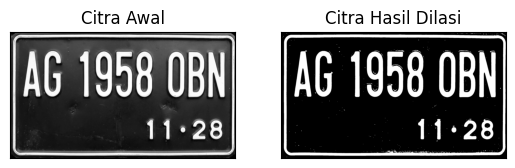

Citra: noisy_text.png
[[1 1 1]
 [1 1 1]
 [1 1 1]]


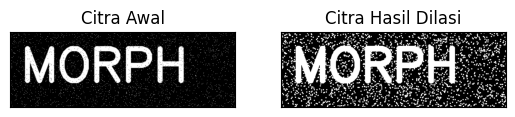

In [6]:
for nama in daftar_file:
    print('Citra:', nama)
    img = cv2.imread(f'{PATH}/{nama}')
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    kernel = np.ones((3,3),np.uint16)
    dilasi = cv2.dilate(thresh,kernel,iterations = 1)
    print(kernel)
    plt.subplot(121),plt.imshow(img,cmap = 'gray'),plt.title('Citra Awal')
    plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(dilasi,cmap = 'gray'),plt.title('Citra Hasil Dilasi')
    plt.xticks([]), plt.yticks([])
    plt.show()

### **Kesimpulan & Analisis**

- **Lebih Simpel**: Penggunaan fungsi bawaan OpenCV jauh lebih praktis dan cepat dibandingkan dengan menulis kode manual menggunakan perulangan bertingkat (*nested loop*).
- **Efek Kernel**: Kernel 3x3 menghasilkan ketebalan yang pas dan tidak berlebihan jika dibandingkan dengan kernel 5x5 sebelumnya. Hamburan *noise* pada gambar teks bising juga tidak terlalu rapat menyatu.
- **Intinya**: Semakin besar ukuran kernel yang dipilih, hasil penebalan objek juga akan semakin tebal.

### **Penjelasan**

- **Erosi**: Kebalikan dari dilasi, berfungsi untuk menipiskan atau mengikis objek putih di dalam gambar biner.
- **Cara Kerja**: Piksel baru akan bernilai putih hanya jika semua piksel di bawah cakupan kernel bernilai putih (mengambil nilai minimum/`np.min`).
- **Kernel**: Digunakan matriks persegi berukuran 5x5, sehingga objek putih yang memiliki ketebalan kurang dari 5 piksel akan otomatis terhapus.

In [7]:
def erosi_citra(F,k):
  m,n= F.shape
  SE= np.ones((k,k), dtype=np.uint8)
  constant= (k-1)//2
  imgE= np.zeros((m,n), dtype=np.uint8)
  for i in range(constant, m-constant):
    for j in range(constant,n-constant):
      temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
      product= temp*SE
      imgE[i,j]= np.min(product)
  return imgE

Citra: plat.jpg


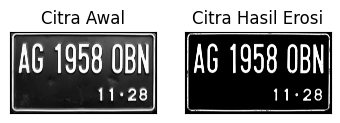

Citra: noisy_text.png


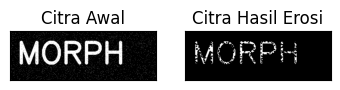

In [8]:
for nama in daftar_file:
    print('Citra:', nama)
    img_e= cv2.imread(f'{PATH}/{nama}',0)
    ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
    k=5
    imgE = erosi_citra(thresh1,k)
    plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.show()

### **Kesimpulan & Analisis**

- **Gambar Plat**: Karakter tulisan menjadi sangat tipis. Garis pembatas luar dan teks kecil `11 • 28` hampir hilang karena ukuran awalnya memang sudah kecil.
- **Gambar Teks Bising**: Sisi baiknya, *noise* bintik-bintik putih di latar belakang bersih total karena ukurannya yang kecil. Sisi buruknya, huruf utama menjadi bolong-bolong akibat *noise* hitam di dalam huruf yang justru melebar.
- **Tips**: Erosi sangat efektif untuk menghapus *noise* putih berukuran kecil, namun perlu kehati-hatian karena objek utama juga akan ikut terkikis.

### **Penjelasan**

- **cv2.erode()**: Fungsi bawaan OpenCV untuk melakukan erosi instan menggunakan kernel persegi 5x5.
- **Langsung Grayscale**: Pada percobaan ini, erosi diterapkan langsung ke gambar asli dalam skala abu-abu tanpa diubah terlebih dahulu ke format biner hitam-putih mutlak.

Citra: plat.jpg


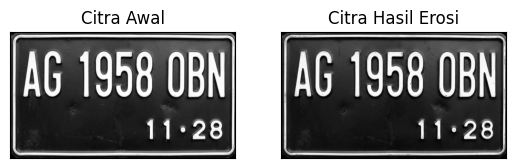

Citra: noisy_text.png


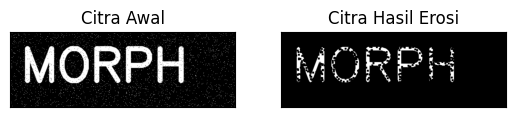

In [9]:
for nama in daftar_file:
    print('Citra:', nama)
    img = cv2.imread(f'{PATH}/{nama}')
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    kernel = np.ones((5,5),np.uint8)
    erosion = cv2.erode(img,kernel,iterations = 1)
    plt.subplot(121),plt.imshow(img,cmap = 'gray'),plt.title('Citra Awal')
    plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(erosion,cmap = 'gray'),plt.title('Citra Hasil Erosi')
    plt.xticks([]), plt.yticks([])
    plt.show()

### **Kesimpulan & Analisis**

- **Sama Saja**: Hasil visual pengikisan menggunakan fungsi bawaan OpenCV ini identik dengan metode manual yang telah dibuat sebelumnya.
- **Efek Grayscale**: Karena diterapkan langsung pada gambar grayscale asli, pengikisan bekerja pada gradasi warna abu-abu sehingga detail halus terasa sedikit berbeda.
- **Kelebihan**: Baris kode menjadi jauh lebih pendek dan waktu eksekusi berjalan jauh lebih cepat.

### **Penjelasan**

- **Opening**: Operasi gabungan berupa proses Erosi yang kemudian dilanjutkan dengan proses Dilasi menggunakan kernel yang sama ($A \circ B = (A \ominus B)
oplus B$).
- **Fungsi**: Sangat efektif untuk menghilangkan objek atau bintik putih kecil tanpa merusak dimensi asli dari objek yang berukuran besar.
- **Skenario**: Pengujian dilakukan dengan dua cara: metode manual dengan kernel 7x7 dan metode otomatis menggunakan fungsi OpenCV `cv2.morphologyEx` dengan kernel 3x3.

Citra: plat.jpg


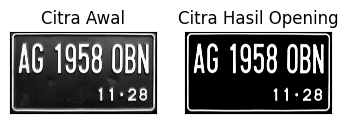

Citra: noisy_text.png


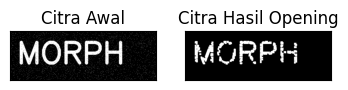

In [10]:
for nama in daftar_file:
    print('Citra:', nama)
    img_o= cv2.imread(f'{PATH}/{nama}',0)
    reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
    k=7
    imgO = dilasi_citra(erosi_citra(thresho,k),k)
    plt.subplot(131),plt.imshow(img_o,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgO,cmap = 'gray')
    plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
    plt.show()

### **Penjelasan**

Di sini proses operasi Opening dijalankan secara otomatis dan cepat menggunakan fungsi bawaan dari OpenCV.

Citra: plat.jpg


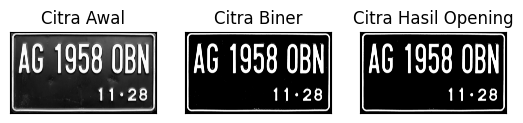

Citra: noisy_text.png


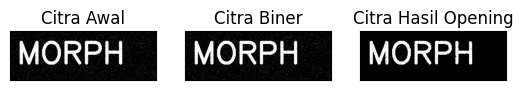

In [11]:
for nama in daftar_file:
    print('Citra:', nama)
    img = cv2.imread(f'{PATH}/{nama}',0)
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    kernel = np.ones((3,3),np.uint8)
    openn = cv2.morphologyEx(thresh,cv2.MORPH_OPEN, kernel)
    plt.subplot(131),plt.imshow(img,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
    plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
    plt.subplot(133),plt.imshow(openn,cmap = 'gray')
    plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
    plt.show()

### **Kesimpulan & Analisis**

- **Cara Manual ($k=7$)**: Pada gambar plat, huruf besar tetap aman namun garis tepi dan teks kecil ikut hilang. Pada gambar teks bising, latar belakang bersih dari bintik putih tetapi tepi huruf utama menjadi agak kasar.
- **Cara OpenCV ($k=3$)**: Detail-detail kecil pada plat nomor terjaga dengan baik. Pada teks bising, bintik putih hilang bersih dan bentuk huruf utama tetap mulus.
- **Catatan**: Operasi Opening hanya bisa menghapus *noise* putih di luar objek (latar belakang), dan tidak dapat menutup lubang hitam di dalam objek utama.

### **Penjelasan**

- **Closing**: Kebalikan dari operasi Opening, yaitu proses Dilasi terlebih dahulu yang kemudian dilanjutkan dengan proses Erosi ($A \bullet B = (A
oplus B) \ominus B$).
- **Fungsi**: Digunakan untuk menutup lubang atau celah hitam kecil di dalam objek, serta menyambung bagian objek yang terputus.
- **Skenario**: Pengujian dilakukan secara manual menggunakan kernel 7x7 dan secara otomatis menggunakan OpenCV dengan kernel 3x3.

Citra: plat.jpg


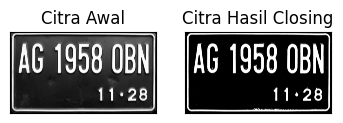

Citra: noisy_text.png


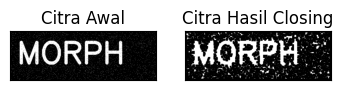

In [12]:
for nama in daftar_file:
    print('Citra:', nama)
    img_c= cv2.imread(f'{PATH}/{nama}',0)
    retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
    k=7
    imgC = erosi_citra(dilasi_citra(threshc,k),k)
    plt.subplot(131),plt.imshow(img_c,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgC,cmap = 'gray')
    plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
    plt.show()

### **Penjelasan**

Di sini dilakukan operasi Closing secara otomatis dan praktis menggunakan fungsi bawaan dari OpenCV.

Citra: plat.jpg


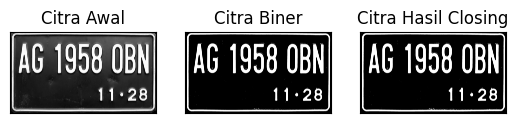

Citra: noisy_text.png


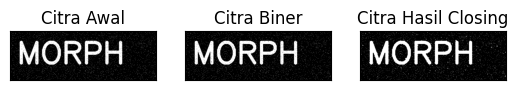

In [13]:
for nama in daftar_file:
    print('Citra:', nama)
    img = cv2.imread(f'{PATH}/{nama}',0)
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    kernel = np.ones((3,3),np.uint8)
    closs = cv2.morphologyEx(thresh,cv2.MORPH_CLOSE, kernel)
    plt.subplot(131),plt.imshow(img,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
    plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
    plt.subplot(133),plt.imshow(closs,cmap = 'gray')
    plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
    plt.show()

### **Kesimpulan & Analisis**

- **Cara Manual ($k=7$)**: Pada gambar plat, celah gelap kecil tertutup dengan rapi. Namun pada gambar teks bising, *noise* putih di latar belakang justru membesar dan menyatu berantakan dengan huruf utama.
- **Cara OpenCV ($k=3$)**: Bentuk huruf pada plat nomor tidak mengalami banyak perubahan. Pada gambar teks bising, lubang di dalam huruf tertutup dengan rapi sehingga terlihat solid, namun *noise* putih di bagian luar tetap ada.
- **Catatan**: Operasi Closing bertugas khusus untuk menutup celah gelap di dalam objek biner, bukan untuk menghilangkan *noise* putih di luar objek.

### **Penjelasan**

- **Cross SE**: Kernel berbentuk salib atau tanda tambah (+), di mana nilai 1 hanya terdapat pada baris dan kolom tengah.
- **Efek Tebal**: Kernel Cross 3x3 menebalkan objek sebanyak 1 piksel ke arah atas, bawah, kiri, dan kanan. Sementara Cross 5x5 menebalkan sejauh 2 piksel pada sumbu utamanya.

In [14]:
def dilasi_citra(F,w):
  p,q= F.shape
  imgD= np.zeros((p,q), dtype=np.uint8)
  SED = np.array([[0, 1, 0],
                  [1, 1, 1],
                  [0, 1, 0]], dtype = np.uint8)
  constant1= (w-1)//2
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

SED = Cross 3
Citra: plat.jpg


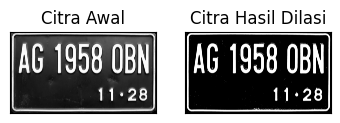

Citra: noisy_text.png


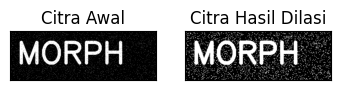

In [15]:
print('SED = Cross 3')
for nama in daftar_file:
    print('Citra:', nama)
    img_d= cv2.imread(f'{PATH}/{nama}',0)
    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
    w=3
    imgD = dilasi_citra(thresh,w)
    plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

### **Penjelasan**

Di bagian ini, proses dilasi dijalankan menggunakan Structuring Element (SE) berbentuk Cross (salib) berukuran 5x5.

In [16]:
def dilasi_citra(F,w):
  p,q= F.shape
  imgD= np.zeros((p,q), dtype=np.uint8)
  SED = np.array([[0, 0, 1, 0, 0],
                  [0, 0, 1, 0, 0],
                  [1, 1, 1, 1, 1],
                  [0, 0, 1, 0, 0],
                  [0, 0, 1, 0, 0]], dtype = np.uint8)
  constant1= (w-1)//2
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

SED = Cross 5
Citra: plat.jpg


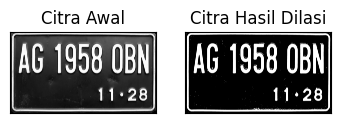

Citra: noisy_text.png


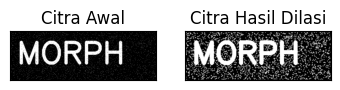

In [17]:
print('SED = Cross 5')
for nama in daftar_file:
    print('Citra:', nama)
    img_d= cv2.imread(f'{PATH}/{nama}',0)
    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
    w=5
    imgD = dilasi_citra(thresh,w)
    plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

### **Kesimpulan & Analisis**

- **Beda Ukuran**: Hasil dilasi menggunakan Cross 5x5 membuat huruf plat nomor terlihat jauh lebih tebal dan padat dibandingkan Cross 3x3, namun celah antar-huruf tetap aman dan tidak saling menempel.
- **Teks Bising**: Pada gambar teks bising, bintik-bintik putih ikut membesar membentuk pola salib kecil. Hal ini membuktikan bahwa gambar bising perlu dibersihkan terlebih dahulu (misalnya menggunakan operasi opening) sebelum proses dilasi diterapkan.

### **Penjelasan**

- **Circular SE**: Kernel berbentuk lingkaran atau elips yang dibuat menggunakan fungsi `cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w,w))`.
- **Bentuk Kecil**: Untuk ukuran kecil seperti 3x3, representasi lingkaran biner akan terlihat sangat mirip dengan bentuk Cross akibat keterbatasan resolusi piksel.

In [18]:
def dilasi_citra(F,w):
  p,q= F.shape
  imgD= np.zeros((p,q), dtype=np.uint8)
  SED= cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(w,w))
  constant1= (w-1)//2
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

SED = Circle 3
Citra: plat.jpg


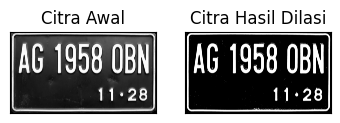

Citra: noisy_text.png


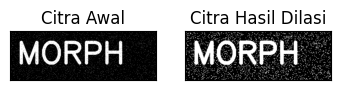

In [19]:
print('SED = Circle 3')
for nama in daftar_file:
    print('Citra:', nama)
    img_d= cv2.imread(f'{PATH}/{nama}',0)
    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
    w=3
    imgD = dilasi_citra(thresh,w)
    plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

SED = Circle 5
Citra: plat.jpg


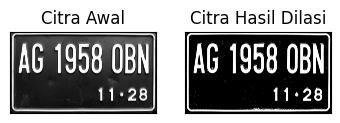

Citra: noisy_text.png


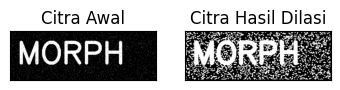

In [20]:
print('SED = Circle 5')
for nama in daftar_file:
    print('Citra:', nama)
    img_d= cv2.imread(f'{PATH}/{nama}',0)
    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
    w=5
    imgD = dilasi_citra(thresh,w)
    plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

### **Kesimpulan & Analisis**

- **Ukuran 3x3**: Hasilnya identik dengan Cross 3x3 karena pada ukuran sekecil ini, representasi piksel lingkaran dan bentuk salib hampir tidak memiliki perbedaan.
- **Ukuran 5x5**: Kernel elips 5x5 memiliki piksel yang lebih padat di bagian sudut dibandingkan dengan Cross 5x5, sehingga hasil penebalannya menjadi lebih merata dengan bentuk membulat halus.
- **Karakter**: Sangat cocok digunakan untuk melebarkan tepi objek secara halus ke segala arah.

### **Penjelasan**

- **Rectangle SE**: Kernel berbentuk persegi panjang dengan ukuran lebar (`p`) dan tinggi (`l`) yang berbeda, dibuat melalui fungsi `cv2.getStructuringElement(cv2.MORPH_RECT, (p,l))`.
- **Asimetris**: Karena dimensinya tidak sama, efek pengikisan akan menunjukkan perbedaan antara arah mendatar (horizontal) dan arah tegak (vertikal).

In [21]:
def erosi_citra(F,p,l):
  m,n= F.shape
  SE = cv2.getStructuringElement(cv2.MORPH_RECT,(p,l))
  constant1= (l-1)//2
  constant2= (p-1)//2
  imgE= np.zeros((m,n), dtype=np.uint8)
  for i in range(constant1, m-constant1):
    for j in range(constant2,n-constant2):
      temp= F[i-constant1:i+constant1+1, j-constant2:j+constant2+1]
      product= temp*SE
      imgE[i,j]= np.min(product)
  return imgE

SE = Rectangle 3x5
Citra: plat.jpg


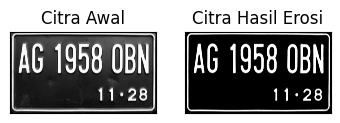

Citra: noisy_text.png


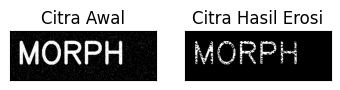

In [22]:
print('SE = Rectangle 3x5')
for nama in daftar_file:
    print('Citra:', nama)
    img_e= cv2.imread(f'{PATH}/{nama}',0)
    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
    p=5
    l=3
    imgE = erosi_citra(thresh1,p,l)
    plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.show()

SE = Rectangle 5x7
Citra: plat.jpg


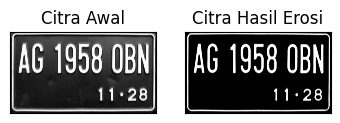

Citra: noisy_text.png


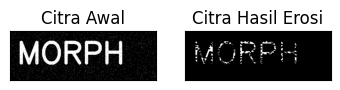

In [23]:
print('SE = Rectangle 5x7')
for nama in daftar_file:
    print('Citra:', nama)
    img_e= cv2.imread(f'{PATH}/{nama}',0)
    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
    p=7
    l=5
    imgE = erosi_citra(thresh1,p,l)
    plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.show()

### **Kesimpulan & Analisis**

- **Teks Bising**: Bintik putih di latar belakang hilang total, tetapi huruf utama menjadi sangat kurus dan muncul banyak lubang di dalamnya.
- **Gambar Plat**: Huruf terkikis lebih banyak ke arah samping dibandingkan arah atas-bawah karena lebar kernel (`p`) lebih besar daripada tingginya (`l`). Pada kernel 5x7, tulisan kecil `11 • 28` bahkan hampir terhapus sepenuhnya.
- **Intinya**: Kernel persegi panjang menghasilkan efek pengikisan asimetris (tidak seimbang) sesuai dengan dimensi yang diatur.

### **Penjelasan**

- **Line Vertikal SE**: Kernel berbentuk garis lurus tegak, dibuat menggunakan fungsi `cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))` dengan ukuran $k$ baris dan 1 kolom.
- **Tujuan**: Operasi ini diterapkan untuk menipiskan objek khusus pada arah vertikal saja.

In [24]:
def erosi_citra(F,k):
  m,n= F.shape
  SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(1,k))
  constant= (k-1)//2
  imgE= np.zeros((m,n), dtype=np.uint8)
  for i in range(constant, m-constant):
    for j in range(constant,n-constant):
      temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
      product= temp*SE
      imgE[i,j]= np.min(product)
  return imgE

SE = Line Vertikal 3
Citra: plat.jpg


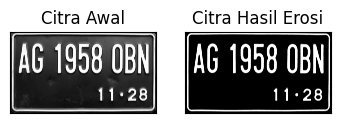

Citra: noisy_text.png


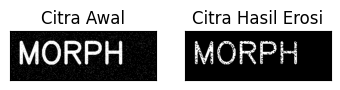

In [25]:
print('SE = Line Vertikal 3')
for nama in daftar_file:
    print('Citra:', nama)
    img_e= cv2.imread(f'{PATH}/{nama}',0)
    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
    k=3
    imgE = erosi_citra(thresh1,k)
    plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.show()

SE = Line Vertikal 5
Citra: plat.jpg


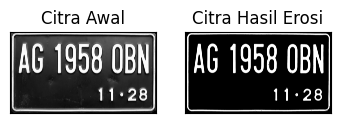

Citra: noisy_text.png


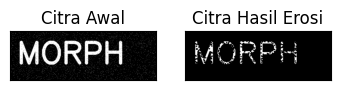

In [26]:
print('SE = Line Vertikal 5')
for nama in daftar_file:
    print('Citra:', nama)
    img_e= cv2.imread(f'{PATH}/{nama}',0)
    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
    k=5
    imgE = erosi_citra(thresh1,k)
    plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.show()

### **Kesimpulan & Analisis**

- **Pengaruh Nilai k**: Semakin panjang garisnya ($k=5$ dibandingkan $k=3$), efek pengikisan tentu akan terlihat semakin jelas.
- **Catatan Kode Manual**: Karena fungsi loop manual masih mengambil potongan gambar lokal berbentuk persegi $k 	imes k$, operasi minimum `np.min` masih mendeteksi tetangga kanan-kiri. Agar hasil benar-benar vertikal murni, jendela pencarian perlu diubah menjadi bentuk kolom tunggal.

### **Penjelasan**

- **Top-hat**: Operasi pengurangan antara gambar asli dengan gambar hasil proses opening: $T(f) = f - (f
circ B)$.
- **Kegunaan**: Digunakan untuk mengambil detail-detail kecil yang terang pada latar belakang yang gelap. Sering diterapkan untuk meratakan pencahayaan gambar sebelum proses konversi ke biner.

Citra: plat.jpg


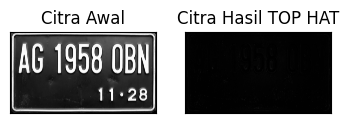

Citra: noisy_text.png


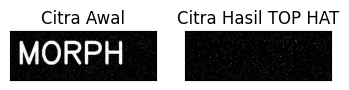

Citra: kitten01 (1).jpg


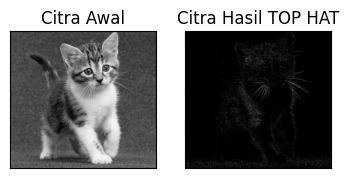

In [27]:
filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)
for nama in daftar_file + ['kitten01 (1).jpg']:
    print('Citra:', nama)
    img = cv2.imread(f'{PATH}/{nama}')
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)
    plt.subplot(131),plt.imshow(img,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(tophat_img,cmap = 'gray')
    plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
    plt.show()

### **Kesimpulan & Analisis**

- **Gambar Plat**: Hasilnya hampir hitam seluruhnya karena huruf-huruf pada plat memiliki ukuran yang jauh lebih besar dibandingkan dengan dimensi kernel (3x3), sehingga tidak terdeteksi sebagai detail kecil.
- **Gambar Teks Bising**: Hanya bintik *noise* putih kecil yang terlihat, sementara huruf utamanya terhapus.
- **Gambar Kucing**: Hasil terlihat luar biasa! Detail tipis yang terang seperti helai kumis dan bulu-bulu halus di tepi tubuh kucing menjadi tampak sangat kontras dan jelas.

### **Penjelasan**

- **Black-hat**: Kebalikan dari operasi Top-hat, yaitu hasil dari proses closing dikurangi dengan gambar asli: $B(f) = (f \bullet B) - f$.
- **Kegunaan**: Digunakan untuk mengisolasi atau mengambil detail-detail kecil yang gelap pada latar belakang yang terang.

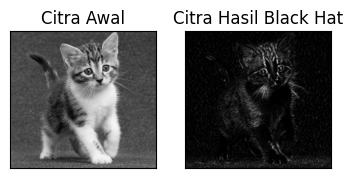

In [28]:
filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)
img = cv2.imread(f'{PATH}/kitten01 (1).jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)
plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(blackhat,cmap = 'gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

### **Kesimpulan & Analisis**

- **Detail Gelap Terlihat**: Operasi Black-hat berhasil memunculkan area gelap yang tipis, seperti bagian pupil mata kucing, lubang hidung, corak belang gelap pada bulu, serta bayangan di lekukan tubuh.
- **Perbedaan dengan Top-hat**: Jika Top-hat mengambil detail terang, Black-hat justru mengisolasi detail yang gelap.
- **Kernel**: Penggunaan kernel asimetris 13x5 di sini sangat membantu untuk mendeteksi struktur bayangan atau garis gelap yang mengarah mendatar (horizontal).

### **Penjelasan**

- **Skeletonization**: Proses untuk mengambil rangka tengah dari suatu objek biner, menghasilkan garis tipis berukuran 1 piksel tanpa merusak bentuk dasar dari objek tersebut.
- **Proses**: Pertama, gambar dikonversi ke format biner menggunakan metode triangle thresholding, kemudian diproses menggunakan fungsi `skeletonize`.

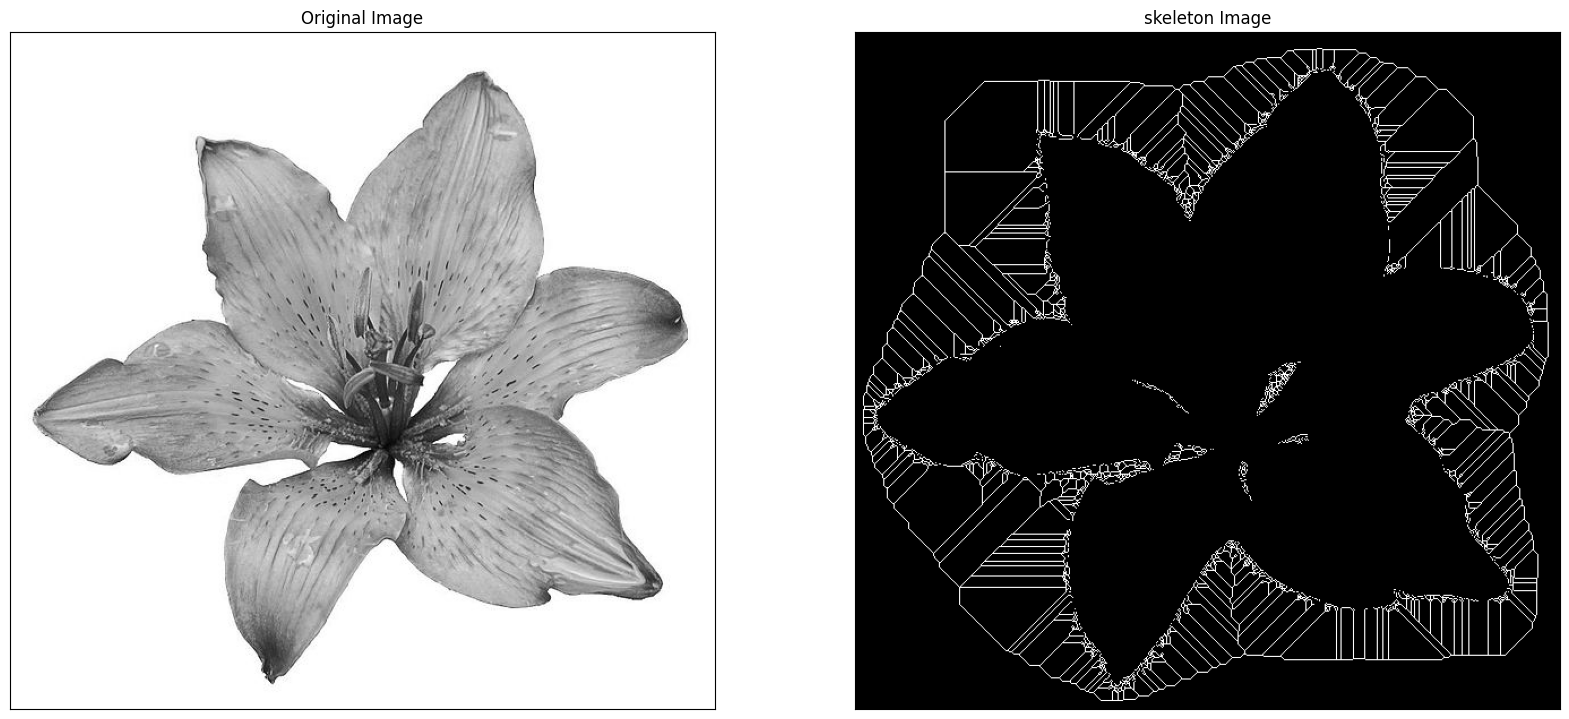

In [29]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize
img = cv.imread(f'{PATH}/lily.jpg',0)
binary = img > filters.threshold_triangle(img)
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0
skeleton = skeletonize(binary_cp)
plt.figure(figsize=(20,20))
plt.subplot(121),plt.imshow(img,cmap = 'gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(skeleton,cmap = 'gray')
plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])
plt.savefig("binary and bin_skeleton.png")
plt.show()

### **Kesimpulan & Analisis**

- **Masalah Latar Belakang**: Gambar bunga lily memiliki latar belakang putih yang dominan. Karena binerisasi menggunakan rumus `img > threshold`, bagian latar belakang putih yang terang justru dianggap sebagai objek utama.
- **Hasil Salah**: Akibatnya, rangka skeleton malah terbentuk di area latar belakang mengelilingi kelopak bunga, sedangkan bagian bunganya sendiri menjadi kosong.
- **Pelajaran**: Kunci utama keberhasilan pembuatan skeleton terletak pada proses binerisasi (pemisahan hitam-putih) di awal. Objek dan latar belakang tidak boleh sampai tertukar.

### **Penjelasan**

- **Koreksi**: Dilakukan perbaikan kesalahan pada Percobaan 15 dengan membalik rumus binerisasinya menjadi `img < threshold`. Sekarang, bagian kelopak bunga yang gelap akan terdeteksi sebagai objek utama.
- **Warna**: Tampilan visual dibalik menggunakan peta warna `gray_r` agar garis rangka skeleton terlihat dengan lebih jelas.

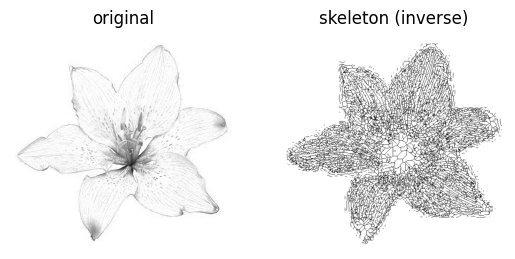

In [30]:
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize
img = io.imread(f'{PATH}/lily.jpg')[..., 0]
binary = img < filters.threshold_triangle(img)
skeleton = skeletonize(binary)
fig, ax = plt.subplots(1, 2)
ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()
plt.show()

### **Kesimpulan & Analisis**

| Parameter | Percobaan 15 | Percobaan 16 |
| :--- | :--- | :--- |
| **Rumus Binerisasi** | `img > threshold` | `img < threshold` |
| **Yang Dianggap Objek** | Latar belakang putih | Bagian bunga yang gelap |
| **Bentuk Rangka** | Garis luar di luar bunga | Garis-garis detail di kelopak |

- **Hasil Sukses**: Setelah binerisasi dibalik, rangka biner yang terbentuk sekarang terpasang dengan tepat mengikuti pola kelopak bunga lily.
- **Detail**: Struktur rangka terlihat cukup rumit karena urat-urat daun serta bintik alami pada kelopak bunga ikut terdeteksi dan dikonversi menjadi garis rangka tipis.

### **Penjelasan**

- **Thinning**: Proses menipiskan objek biner secara berulang-ulang hingga menyisakan garis setebal 1 piksel.
- **Cara Kerja**: Operasi bekerja melalui pencocokan pola *hit-or-miss* secara berulang.
- **Komparasi**: Hasil penipisan ini akan dibandingkan secara visual dengan hasil proses skeletonize sebelumnya.

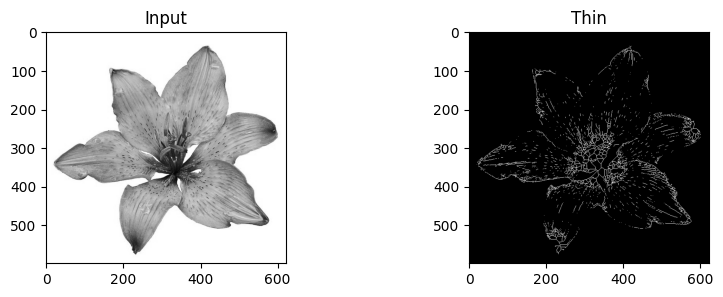

In [31]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt
image = img_as_float(color.rgb2gray(io.imread(f'{PATH}/lily.jpg')))
image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)
f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))
ax0.imshow(image, cmap='gray')
ax0.set_title('Input')
ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')
plt.savefig('/tmp/char_out.png')
plt.show()

### **Kesimpulan & Analisis**

- **Hasil Thin**: Fungsi `thin` berhasil menghasilkan rangka kelopak bunga setebal 1 piksel berdasarkan batas hitam-putih yang diatur (`image < 0.5`).
- **Alasan Perbedaan**: Hasilnya berbeda jauh dengan Percobaan 15 karena di sini fokus diarahkan untuk menipiskan kelopak bunga (objek gelap), bukan latar belakang putih.
- **Intinya**: Baik metode `thinning` maupun `skeletonize` sama-sama efektif untuk menghasilkan garis rangka tipis tunggal, asalkan proses binerisasi di awal sudah dilakukan dengan benar.